# Environments {#sec-environments}

In this section, we introduce different environments we can test DDRL in:
* the two-armed bandit task
* the risk-reward dilemma
* two social dilemmas: the stag-hunt game and the prisoner's dilemma

First, we import what we need:

In [ ]:
# imports for testing
import matplotlib.pyplot as plt
import numpy as np

# test environments
from pyCRLD.Environments.DistTwoArmedBanditOneState import DistTwoArmedBanditOneState
from pyCRLD.Environments.RiskRewardDilemma import RiskRewardDilemma
from pyCRLD.Environments.SocialDilemma import SocialDilemma

# test agent
from pyCRLD.Agents.Base import abase
from pyCRLD.Agents.StrategySARSA import stratSARSA

# utils
from pyCRLD.Utils import FlowPlot as fp
from pyCRLD.Utils.Trajectories1D import trajectories_1D 
from pyCRLD.Utils.PhasePlot import phaseplot

## Two-armed bandit task

The two-armed bandit is a standard task to study decision-making in cognitive psychology. In this task, an agent must choose between two options, $a_1$ and $a_2$. $a_1$ gives a reward $+1$ with probability $p_1$, and a punishment $-1$ with probability $1 - p_1$. $a_2$ gives a reward $+1$ with probability $p_2$, and a punishment $-1$ with probability $1 - p_2$. Choosing repeatedly between the two options, the agent must learn which one is most rewarding on average. We model the two-armed bandit task as a simple, 1-state Markov environment:

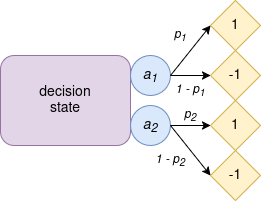

Below, we define a two-armed bandit task with $p_1 = 0.7$ and $p_2 = 0.3$. 

In [ ]:
# Define environment
xs = np.array([[-1, 1],
               [-1, 1]])
ps = np.array([[0.3, 0.7],
               [0.7, 0.3]])
tab = DistTwoArmedBanditOneState(disttype='discrete', xs=xs, ps=ps)

Now, we define an agent-environment interface comprised of a SARSA agent playing the aforementioned task. This agent has a learning rate $\alpha=0.1$, a discount factor $\gamma = 0$, and a choice intensity $\beta = 4$. 

In [ ]:
# Agent-environment interface
aei = stratSARSA(tab,
                 learning_rates=0.1,
                 discount_factors=0,
                 choice_intensities=4.,
                 use_prefactor=False)

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


We can plot the agent's deterministic trajectories and phase plot. Both plots show what strategy the agent converges to. In the phase plot, the fixed points are the intersections of the $dX$ curve with $0$. In the phase plot, we also showed the value of the RPE given a strategy $X$ (in blue). 

Text(0.5, 1.0, 'phase plot')

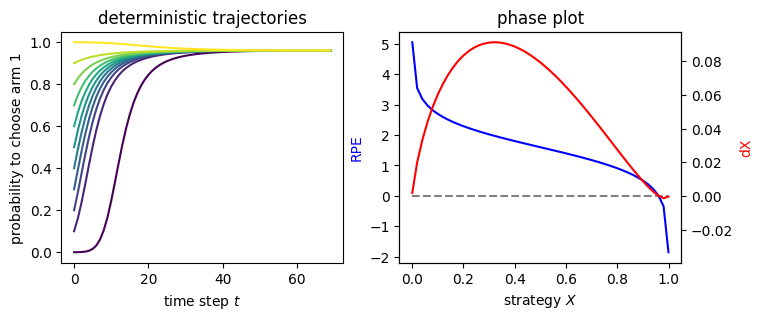

In [ ]:
# Figure
x = ([0], [0], [0])  # (i,s,a) to plot along the x-axis
res = np.linspace(0, 1., 11)  # initial strategies
res[0] = 0.0001
res[-1] = 0.9999
res_phase = np.linspace(0, 1., 51)  # resolution for phase plot
res_phase[0] = 0.001
res_phase[-1] = 0.999

# Plot deterministic trajectories and phase plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))
trajectories_1D(aei, x, res, NrRandom=1, traj_len=70, axes=[ax1])
phaseplot(aei, x, res_phase, NrRandom=1, axes=[ax2])
ax1.set_title("deterministic trajectories")
ax1.set_xlabel("time step "+r'$t$')
ax1.set_ylabel("probability to choose arm 1")
ax2.set_xlabel("strategy "+r'$X$')
ax2.set_title("phase plot")

## Risk-reward dilemma

In a risk-reward dilemma, an agent can choose between a risky action, $r$, and a safe action, $s$. The environment contains a prosperous state and a degraded state. In the prosperous state, the risky action yields a higher reward than the safe action. However, choosing $r$ also makes it more likely to transition to the degraded state, in which rewards are always null. In the degraded state, only the safe action gives the agent a chance to transition back to the prosperous state. 

We use the following risk-reward dilemma, which we also implement below.

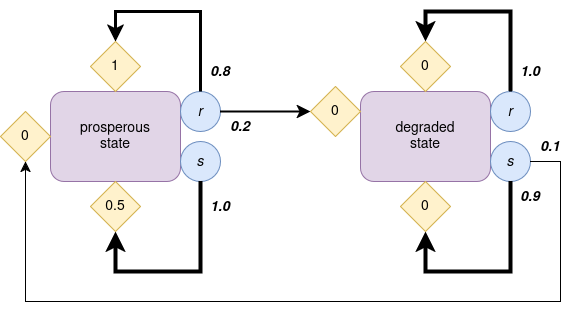

In [ ]:
# Define environment
rrd = RiskRewardDilemma(pc=0.1, pr=0.2, rc=0.5, rr=1, rd=0)

Now, we define an agent-environment interface comprised of a SARSA agent playing the aforementioned task. This agent has a learning rate $\alpha=0.1$, a discount factor $\gamma = 0.9$, and a choice intensity $\beta = 50$. 

In [ ]:
# Agent-environment interface
aei = stratSARSA(rrd,
                 learning_rates=0.1,
                 discount_factors=0.9,
                 choice_intensities=50.,
                 use_prefactor=True)

We plot the agent's deterministic trajectories in phase space on the flow plot below:

Text(0, 0.5, 'prob. safe action in deg. state')

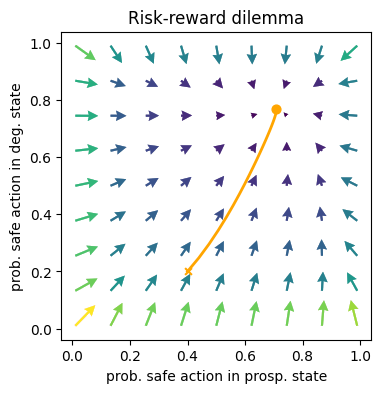

In [ ]:
# Figure
x = ([0], [0], [0])  # (i,s,a) to plot along the x-axis
y = ([0], [1], [0])  # (i,s,a) to plot along the y-axis

# Plot flow plot
fig, ax1 = plt.subplots(1, 1, figsize=(4, 4))
fp.plot_strategy_flow(aei, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), 
                      NrRandom=16, axes=ax1)
# Sample trajectory
Xinit = np.ones((1,2,2)) * 0.4
Xinit[:,1,0] = 0.2
Xinit[:,:,1] = 1 - Xinit[:,:,0]  # initial strategy
trj, fpr = aei.trajectory(Xinit, Tmax=1000, tolerance=1e-6)  # compute traj
fp.plot_trajectories([trj], x, y, fprs=[fpr], axes=ax1, cols=['orange'])
ax1.set_title("Risk-reward dilemma")
ax1.set_xlabel("prob. safe action in prosp. state")
ax1.set_ylabel("prob. safe action in deg. state")

## Social dilemmas

Here, we consider two social dilemmas: the stag-hunt game and the prisoner's dilemma.

The stag-hunt game is a type of social dilemma where two or more agents must coordinate on the best action. Hence, it is often called a "coordination problem". In our version, we consider two agents who must take one of two actions: cooperate ($c$) or defect ($d$). 

If both agents cooperate, they get a payoff $R$ (called "reward"). If they both defect, they get a payoff $P$ (called "punishment"). If one cooperates and the other defects, the cooperator gets a payoff $S$ (called "sucker") and the defector, a payoff $T$ (called "temptation"). In a stag-hunt game, $R > T > P > S$. This means the agents' main challenge is coordination: cooperating at the same time in order to get the maximum reward. 

Note that, if $T > R > P > S$, the game becomes a prisoner's dilemma: both agents are incentivized to defect, because the temptation is now the maximum payoff. 

The structure of a social dilemma is shown below.

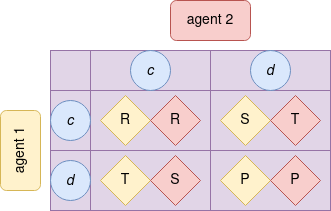

In [ ]:
# Define environments
envSH = SocialDilemma(R=3, T=1, P=0, S=-2)  # stag hunt
envPD = SocialDilemma(R=1, T=3, P=0, S=-2)  # prisoner's dilemma

Now, we define an agent-environment interface comprised of a SARSA agent playing the aforementioned tasks. This agent has a learning rate $\alpha=0.1$, a discount factor $\gamma = 0.9$, and a choice intensity $\beta = 50$. 

In [ ]:
# Agent-environment interface
aeiSH = stratSARSA(envSH,
                   learning_rates=0.1,
                   discount_factors=0.9,
                   choice_intensities=50.,
                   use_prefactor=True)

aeiPD = stratSARSA(envPD,
                   learning_rates=0.1,
                   discount_factors=0.9,
                   choice_intensities=50.,
                   use_prefactor=True)

We plot the agent's deterministic trajectories in phase space on the flow plots below:

Text(0, 0.5, 'prob. agent 2 cooperates')

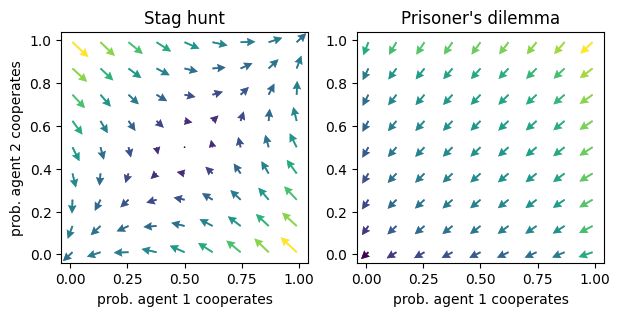

In [ ]:
# Figure
x = ([0], [0], [0])  # (i,s,a) to plot along the x-axis
y = ([1], [0], [0])  # (i,s,a) to plot along the y-axis

# Plot flow plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3))
fp.plot_strategy_flow(aeiSH, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), 
                      NrRandom=16, axes=ax1)
fp.plot_strategy_flow(aeiPD, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), 
                      NrRandom=16, axes=ax2)
ax1.set_title("Stag hunt")
ax2.set_title("Prisoner's dilemma")
ax1.set_xlabel("prob. agent 1 cooperates")
ax2.set_xlabel("prob. agent 1 cooperates")
ax1.set_ylabel("prob. agent 2 cooperates")